In [1]:
import netCDF4 as nc
import glob
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import xrft
from scipy.io import loadmat
import scipy.io as sio
from scipy.special import gamma, kv
from numpy.linalg import inv
# import cartopy.crs as ccrs
# import cartopy.feature as cfeature
from scipy.stats import chi2
import swot_analysis as swot
from matplotlib import pyplot as plt, animation
import h5py
from scipy.ndimage import gaussian_filter
from scipy.optimize import curve_fit
import mpmath as mp
import datetime
from matplotlib import pyplot as plt, animation
import scipy.stats as stats
import pandas as pd
import math
import pickle
import zipfile
import matplotlib.patches as patches
import matplotlib.gridspec as gridspec
import matplotlib.ticker as ticker
import warnings

In [2]:
with open('GSExtension_reselect_sim.pkl', 'rb') as f:
    data_GS = pickle.load(f)

In [3]:
with open('Oleander_reselect_sim.pkl', 'rb') as f:
    data_Ol = pickle.load(f)

In [4]:
spectra_tot_combined_GS = data_GS['spectra_tot_combined']
ssha_tot_combined_GS    = data_GS['ssha_tot_combined']
lon_strip_tot_GS        = data_GS['lon_strip_tot']
lat_strip_tot_GS        = data_GS['lat_strip_tot']
ssha_mean2side_GS       = data_GS['ssha_mean2side']

In [5]:
spectra_tot_combined_Ol = data_Ol['spectra_tot_combined']
ssha_tot_combined_Ol    = data_Ol['ssha_tot_combined']
lon_strip_tot_Ol        = data_Ol['lon_strip_tot']
lat_strip_tot_Ol        = data_Ol['lat_strip_tot']
ssha_mean2side_Ol       = data_Ol['ssha_mean2side']

In [6]:
track_length_Ol = 350 # Ol
track_length_GS = 350 # GS
fitkGS = 35
fitkOl = 35
dx = 2e3
k_GS = np.fft.rfftfreq(track_length_GS, dx)# rfft wave number cpm
k_Ol = np.fft.rfftfreq(track_length_Ol, dx)# rfft wave number cpm

In [7]:
def balanced_fit(k,A,k0,s0): # for balanced part
    return A/(1 + (k/k0)**(s0))

def matern_spec_new(k,s,A_s): # for small-scale part
    return 2*np.pi*A_s/((1+(100e3*k)**2)**(s/2))

def F_new(k,A,k0,s0,s,A_s):
    return np.log(balanced_fit(k,A,k0,s0)+ matern_spec_new(k,s,A_s)) 

def F_balanced(k,A,k0,s0):
    return np.log(balanced_fit(k,A,k0,s0))

### Fit the mean spectrum for the Gulf Stream Region

In [8]:
#initial guesses
k0init = 8e-6
s0init = 5
# pinit = 1

ss = 1.2
As0 = 0.5

wnew = np.sqrt(k_GS[1:])

In [9]:
numGS = (
    spectra_tot_combined_GS
    .drop_duplicates(subset=["month", "dates", "position"])
    .groupby("month")
    .size()
)

# print(num)

In [12]:
meanumGS = np.sum(numGS)

In [15]:
mean_spectrum = np.mean(np.stack(spectra_tot_combined_GS['spectrum'].values), axis=0)
Ainit = mean_spectrum[1]

In [16]:
popcoefmean,popcovmean = curve_fit(F_new, k_GS[1:], np.log(mean_spectrum[1:]), \
                                    p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                    bounds=([0, 0, 0, 0, 0], \
                                            [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)

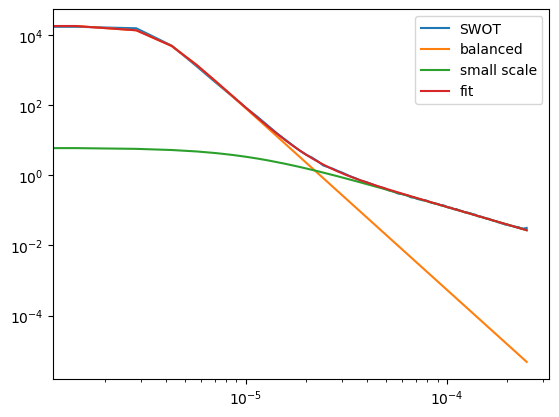

In [18]:
plt.loglog(k_GS,mean_spectrum,label = 'SWOT')
plt.loglog(k_GS,balanced_fit(k_GS,*popcoefmean[0:3]),label = 'balanced')
plt.loglog(k_GS,matern_spec_new(k_GS,*popcoefmean[3:]),label = 'small scale')
plt.loglog(k_GS,balanced_fit(k_GS,*popcoefmean[0:3])+matern_spec_new(k_GS,*popcoefmean[3:]),label = 'fit')
plt.legend()

In [32]:
nu = 2 * meanumGS     # if 20 independent spectra, each with 2 dof
B = 1000          # number of Monte Carlo samples

P_fit = balanced_fit(k_GS[1:],*popcoefmean[0:3])+matern_spec_new(k_GS[1:],*popcoefmean[3:])

theta_boot = []

for b in range(B):
    noise = np.random.chisquare(nu, size=len(k_GS[1:])) / nu
    P_synthetic = P_fit * noise
    popcoefr,popcovr = curve_fit(F_new, k_GS[1:], np.log(P_synthetic), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9,1e9,1e9]),maxfev=5000)
    theta_boot.append(popcoefr)

theta_boot = np.array(theta_boot)
slope_boot = theta_boot[:, 2] 

# Example 95% confidence interval for parameter index m
lower_GS = np.percentile(slope_boot, 2.5)
upper_GS = np.percentile(slope_boot, 97.5)

## Gulf Stream extension

#### SWOT

In [10]:
lowermGS = np.empty((12,))
uppermGS = np.empty((12,))
medianmGS = np.empty((12,))
B = 1000          # number of Monte Carlo samples

In [11]:
numGS

month
1.0     21
2.0     21
3.0     30
4.0     26
5.0     13
6.0     22
7.0     13
8.0     26
9.0     18
10.0    36
11.0    21
12.0    31
dtype: int64

In [12]:
mean_spectrum = np.mean(np.stack(spectra_tot_combined_GS['spectrum'].values), axis=0)
Ainit = mean_spectrum[1]
monthly_mean_spectra = spectra_tot_combined_GS.groupby('month')['spectrum'].apply(
    lambda x: np.mean(np.stack(x), axis=0)
)

In [13]:
for m in range(0,12):
    nu = 2 * numGS[m+1]     # if 20 independent spectra, each with 2 dof
    # nu = 2 * 20
    popcoefm,popcovm = curve_fit(F_new, k_GS[1:], np.log(monthly_mean_spectra.values[m][1:]), \
                                    p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                    bounds=([0, 0, 0, 0, 0], \
                                            [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
    P_fit = matern_spec_new(k_GS[1:],*popcoefm[3:])+balanced_fit(k_GS[1:],*popcoefm[0:3])
    
    theta_boot = []
    
    for b in range(B):
        noise = np.random.chisquare(nu, size=len(k_GS[1:])) / nu
        P_synthetic = P_fit * noise
        try: 
            with warnings.catch_warnings():
                warnings.filterwarnings("error", category=RuntimeWarning)
                popcoefm,_ = curve_fit(F_new, k_GS[1:], np.log(P_synthetic), \
                                            p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                            bounds=([0, 0, 0, 0, 0], \
                                                    [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
        except (RuntimeWarning, RuntimeError, ValueError):
            continue
    
        # theta_b = fit_spectrum(k, P_synthetic)
        theta_boot.append(popcoefm)
    
    theta_boot = np.array(theta_boot)
    slope_boot = theta_boot[:, 2] #+ theta_boot[:, 3]
    
    # Example 95% confidence interval for parameter index m
    lowermGS[m] = np.percentile(slope_boot, 2.5)
    uppermGS[m] = np.percentile(slope_boot, 97.5)
    medianmGS[m] = np.percentile(slope_boot, 50)

In [14]:
slopedata = np.load('GSExtension_monthlyslope_reselect.npy',allow_pickle='TRUE').item()
for key, value in slopedata.items():
    globals()[key] = value

Text(0, 0.5, 'Spectral slope')

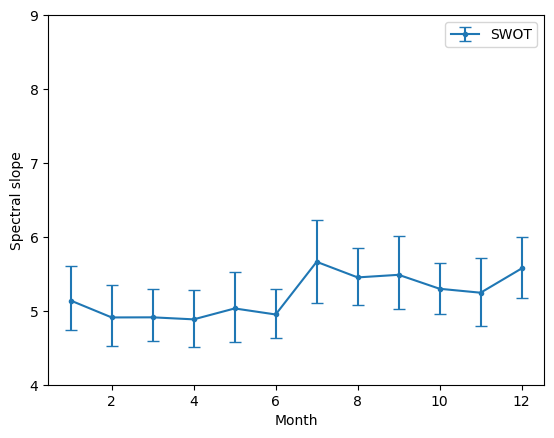

In [15]:
x = np.arange(1, 13)

y = np.array(slopemonthly_GS)
# y = medianmGS
lower = np.array(lowermGS)
upper = np.array(uppermGS)

yerr = np.vstack([y - lower, upper - y])

plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='SWOT')
plt.ylim((4,9))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

#### simulation

In [33]:
# # load simulation spectra
# with open('GSExtension_sim.pkl', 'rb') as f:
#     data = pickle.load(f)
# ssha_tot_combined = data['ssha_tot_combined']

In [16]:
num_sim = (
    ssha_tot_combined_GS
    .drop_duplicates(subset=["month", "dates", "position"])
    .groupby("month")
    .size()
)

# print(num_sim)

In [17]:
monthly_mean_spectra_sim = ssha_tot_combined_GS.groupby('month')['spectra_simulation'].apply(
    lambda x: np.mean(np.stack(x), axis=0)
)

lowerm_simGS = np.empty((12,))
upperm_simGS = np.empty((12,))
medianm_simGS = np.empty((12,))
B = 1000          # number of Monte Carlo samples
# fitk = 34

In [18]:
for m in range(0,12):
    nu = 2 * num_sim[m+1]     # if 20 independent spectra, each with 2 dof
    # nu = 2 * 20
    popcoefm_sim,popcovm_sim = curve_fit(F_balanced, k_GS[1:fitkGS], np.log(monthly_mean_spectra_sim.values[m][1:fitkGS]), \
                                    p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_GS[1:fitkGS]), absolute_sigma=True,\
                                    bounds=([0, 0, 0], \
                                            [1e9, 1e9, 1e9]),maxfev=5000)
    P_fit = balanced_fit(k_GS[1:fitkGS],*popcoefm_sim)
    
    theta_boot = []
    
    for b in range(B):
        noise = np.random.chisquare(nu, size=len(k_GS[1:fitkGS])) / nu
        P_synthetic = P_fit * noise
        try: 
            popcoefm,_ = curve_fit(F_balanced, k_GS[1:fitkGS], np.log(P_synthetic), \
                                        p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_GS[1:fitkGS]), absolute_sigma=True,\
                                        bounds=([0, 0, 0], \
                                                [1e9, 1e9, 1e9]),maxfev=5000)
        
            # theta_b = fit_spectrum(k, P_synthetic)
            theta_boot.append(popcoefm)
        except RuntimeError:
            continue
    
    theta_boot = np.array(theta_boot)
    slope_boot = theta_boot[:, 2] #+ theta_boot[:, 3]
    
    # Example 95% confidence interval for parameter index m
    lowerm_simGS[m] = np.percentile(slope_boot, 2.5)
    upperm_simGS[m] = np.percentile(slope_boot, 97.5)
    medianm_simGS[m] = np.percentile(slope_boot, 50)

Text(0, 0.5, 'Spectral slope')

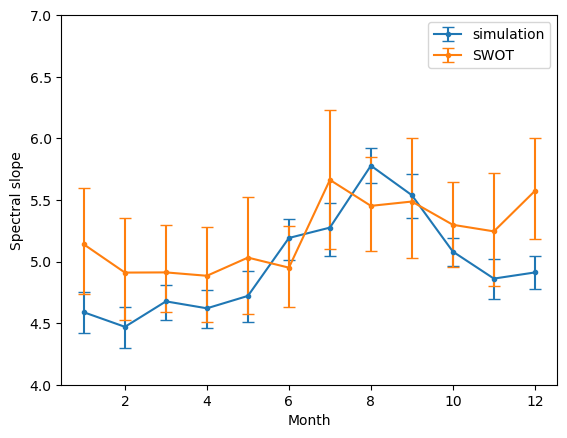

In [19]:
x = np.arange(1, 13)

y = np.array(slopemonthly_sim_GS)
# y = medianm_sim
lower = np.array(lowerm_simGS)
upper = np.array(upperm_simGS)
yerr = np.vstack([y - lower, upper - y])
plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='simulation')

y = np.array(slopemonthly_GS)
# y = medianmGS
lower = np.array(lowermGS)
upper = np.array(uppermGS)

yerr = np.vstack([y - lower, upper - y])

plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='SWOT')

plt.ylim((4,7))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')
# plt.savefig('../plots/monthlyslope_GSextension_reselect.png')

## Oleander 

In [35]:
numOl = (
    spectra_tot_combined_Ol
    .drop_duplicates(subset=["month", "dates", "position"])
    .groupby("month")
    .size()
)

# print(numOl)

### Fit time-mean

In [40]:
meanumOl = np.sum(numOl)

In [39]:
mean_spectrumOl = np.mean(np.stack(spectra_tot_combined_Ol['spectrum'].values), axis=0)
Ainit = mean_spectrumOl[1]

In [41]:
popcoefmeanOl,popcovmeanOl = curve_fit(F_new, k_Ol[1:], np.log(mean_spectrumOl[1:]), \
                                    p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                    bounds=([0, 0, 0, 0, 0], \
                                            [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)

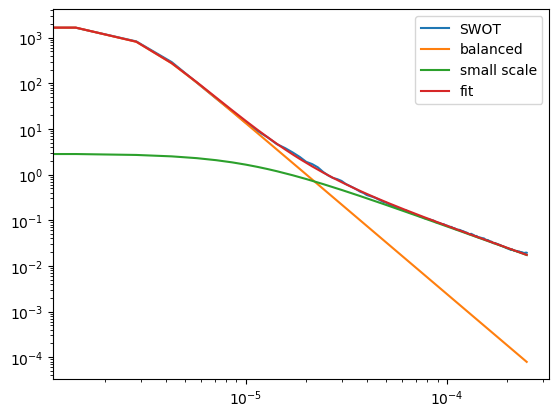

In [44]:
plt.loglog(k_Ol,mean_spectrumOl,label = 'SWOT')
plt.loglog(k_Ol,balanced_fit(k_Ol,*popcoefmeanOl[0:3]),label = 'balanced')
plt.loglog(k_Ol,matern_spec_new(k_Ol,*popcoefmeanOl[3:]),label = 'small scale')
plt.loglog(k_Ol,balanced_fit(k_Ol,*popcoefmeanOl[0:3])+matern_spec_new(k_Ol,*popcoefmeanOl[3:]),label = 'fit')
plt.legend()

In [45]:
nu = 2 * meanumOl     # if 20 independent spectra, each with 2 dof
B = 1000          # number of Monte Carlo samples

P_fit = balanced_fit(k_Ol[1:],*popcoefmeanOl[0:3])+matern_spec_new(k_Ol[1:],*popcoefmeanOl[3:])

theta_boot = []

for b in range(B):
    noise = np.random.chisquare(nu, size=len(k_Ol[1:])) / nu
    P_synthetic = P_fit * noise
    popcoefr,popcovr = curve_fit(F_new, k_Ol[1:], np.log(P_synthetic), \
                                p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnew, absolute_sigma=True,\
                                bounds=([0, 0, 0, 0, 0], \
                                        [1e9, 1e9, 1e9,1e9,1e9]),maxfev=5000)
    theta_boot.append(popcoefr)

theta_boot = np.array(theta_boot)
slope_boot = theta_boot[:, 2] 

# Example 95% confidence interval for parameter index m
lower_Ol = np.percentile(slope_boot, 2.5)
upper_Ol = np.percentile(slope_boot, 97.5)

In [52]:
print('Sargasso upper: ', upper_Ol)
print('Sargasso lower: ', lower_Ol)
print('GS extension upper: ', upper_GS)
print('GS extension lower: ', lower_GS)

Sargasso upper:  3.900585955383224
Sargasso lower:  3.610002040483331
GS extension upper:  5.2975083797443485
GS extension lower:  5.059667664862585


In [36]:
lowermOl = np.empty((12,))
uppermOl = np.empty((12,))
medianmOl = np.empty((12,))
B = 1000 
mean_spectrum = np.mean(np.stack(spectra_tot_combined_Ol['spectrum'].values), axis=0)
Ainit = mean_spectrum[1]
monthly_mean_spectraOl = spectra_tot_combined_Ol.groupby('month')['spectrum'].apply(
    lambda x: np.mean(np.stack(x), axis=0)
)
wnewOl = np.sqrt(k_Ol[1:])

In [37]:
import warnings

In [23]:
for m in range(0,12):
    nu = 2 * numOl[m+1]     # if 20 independent spectra, each with 2 dof
    # nu = 2 * 20
    popcoefmOl,popcovmOl = curve_fit(F_new, k_Ol[1:], np.log(monthly_mean_spectraOl.values[m][1:]), \
                                    p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnewOl, absolute_sigma=True,\
                                    bounds=([0, 0, 0, 0, 0], \
                                            [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
    P_fit = matern_spec_new(k_Ol[1:],*popcoefmOl[3:])+balanced_fit(k_Ol[1:],*popcoefmOl[0:3])
    
    theta_boot = []
    
    for b in range(B):
        noise = np.random.chisquare(nu, size=len(k_Ol[1:])) / nu
        P_synthetic = P_fit * noise
        try:
            with warnings.catch_warnings():
                warnings.filterwarnings("error", category=RuntimeWarning)
                popcoefm,_ = curve_fit(F_new, k_Ol[1:], np.log(P_synthetic), \
                                            p0 = [Ainit,k0init,s0init,ss,As0],sigma = wnewOl, absolute_sigma=True,\
                                            bounds=([0, 0, 0, 0, 0], \
                                                    [1e9, 1e9, 1e9, 1e9,1e9]),maxfev=5000)
                theta_boot.append(popcoefm)
        except (RuntimeWarning, RuntimeError, ValueError):
            continue

            
            
    
    theta_boot = np.array(theta_boot)
    slope_boot = theta_boot[:,2] #+ theta_boot[:, 3]
    
    # Example 95% confidence interval for parameter index m
    lowermOl[m] = np.percentile(slope_boot, 2.5)
    uppermOl[m] = np.percentile(slope_boot, 97.5)
    medianmOl[m] = np.percentile(slope_boot, 50)

In [24]:
slopedataol = np.load('Oleander_monthlyslope_reselect.npy',allow_pickle='TRUE').item()
for key, value in slopedataol.items():
    globals()[key] = value

Text(0, 0.5, 'Spectral slope')

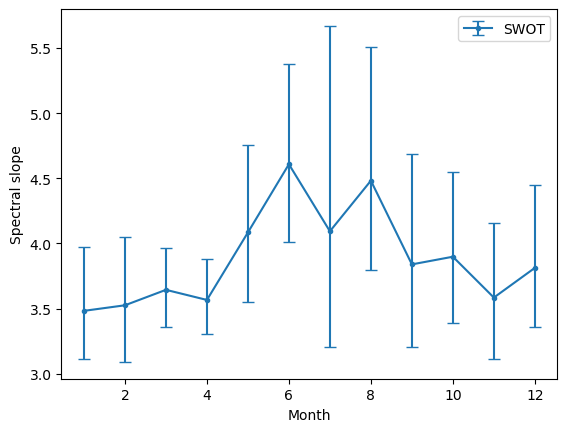

In [25]:
x = np.arange(1, 13)

y = np.array(slopemonthly_Ol)
# y = medianmOl
lower = np.array(lowermOl)
upper = np.array(uppermOl)

yerr = np.vstack([y - lower, upper - y])

plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='SWOT')
# plt.ylim((3,8))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

In [26]:
# with open('Oleander_sim.pkl', 'rb') as f:
#     data = pickle.load(f)
# ssha_tot_combinedOl = data['ssha_tot_combined']

In [27]:
num_simOl = (
    ssha_tot_combined_Ol
    .drop_duplicates(subset=["month", "dates", "position"])
    .groupby("month")
    .size()
)

In [28]:
monthly_mean_spectra_simOl = ssha_tot_combined_Ol.groupby('month')['spectra_simulation'].apply(
    lambda x: np.mean(np.stack(x), axis=0)
)

lowerm_simOl = np.empty((12,))
upperm_simOl = np.empty((12,))
medianm_simOl = np.empty((12,))
B = 1000          # number of Monte Carlo samples
# fitk = 29

In [29]:
for m in range(0,12):
    nu = 2 * num_simOl[m+1]     # if 20 independent spectra, each with 2 dof
    # nu = 2 * 20
    popcoefm_simOl,_ = curve_fit(F_balanced, k_Ol[1:fitkOl], np.log(monthly_mean_spectra_simOl.values[m][1:fitkOl]), \
                                    p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_Ol[1:fitkOl]), absolute_sigma=True,\
                                    bounds=([0, 0, 0], \
                                            [1e9, 1e9, 1e9]),maxfev=5000)
    P_fit = balanced_fit(k_Ol[1:fitkOl],*popcoefm_simOl)
    
    theta_boot = []
    
    for b in range(B):
        try: 
            
            noise = np.random.chisquare(nu, size=len(k_Ol[1:fitkOl])) / nu
            P_synthetic = P_fit * noise
            popcoefm,_ = curve_fit(F_balanced, k_Ol[1:fitkOl], np.log(P_synthetic), \
                                        p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_Ol[1:fitkOl]), absolute_sigma=True,\
                                        bounds=([0, 0, 0], \
                                                [1e9, 1e9, 1e9]),maxfev=5000)
    
            theta_boot.append(popcoefm)
        except RuntimeError:
            continue
    
    theta_boot = np.array(theta_boot)
    slope_boot = theta_boot[:,2] #+ theta_boot[:, 3]
    
    # Example 95% confidence interval for parameter index m
    lowerm_simOl[m] = np.percentile(slope_boot, 2.5)
    upperm_simOl[m] = np.percentile(slope_boot, 97.5)
    medianm_simOl[m] = np.percentile(slope_boot, 50)

Text(0, 0.5, 'Spectral slope')

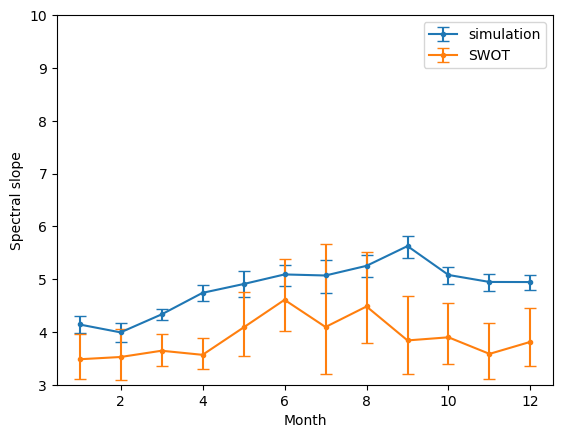

In [31]:
x = np.arange(1, 13)

y = np.array(slopemonthly_sim_Ol)
# y = medianm_simOl
lower = np.array(lowerm_simOl)
upper = np.array(upperm_simOl)
yerr = np.vstack([y - lower, upper - y])
plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='simulation')

y = np.array(slopemonthly_Ol)
# y = medianmOl
lower = np.array(lowermOl)
upper = np.array(uppermOl)

yerr = np.vstack([y - lower, upper - y])

plt.errorbar(x, y, yerr=yerr,fmt='.-',capsize=4,label='SWOT')
plt.ylim((3,10))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')
# plt.savefig('../plots/monthlyslope_Oleander_reselect.png')

## KE spectral fit 

In [46]:
g = 9.8
f_ol = 7.705793472939289e-05
f_gs = 9.346165368838241e-05

In [47]:
def balanced_ke_gs(k, A, k0, s0):
    # return A * k**2 / (1.0 + (k / k0)**s0)
    return 0.5*g**2*(2*np.pi)**2*A * k**2 / (1.0 + (k / k0)**s0)/f_gs**2

def F_balanced_ke_gs(k, A, k0, s0):
    return np.log(balanced_ke_gs(k, A, k0, s0))

def balanced_ke_ol(k, A, k0, s0):
    # return A * k**2 / (1.0 + (k / k0)**s0)
    return 0.5*g**2*(2*np.pi)**2*A * k**2 / (1.0 + (k / k0)**s0)/f_ol**2

def F_balanced_ke_ol(k, A, k0, s0):
    return np.log(balanced_ke_ol(k, A, k0, s0))

In [48]:
# load KE spectra 
KEsimspectraGS = np.load('KEsimdailymean_GSextension_new_swath_reselect_rotate_anom.npy',allow_pickle='TRUE').item()
KEsimspectraOl = np.load('KEsimdailymean_Oleander_new_swath_reselect_rotate_anom.npy',allow_pickle='TRUE').item()

In [49]:
# KE_spectra_simGS = 0.5*(KEsimspectraGS['u_spectra_sim']+ KEsimspectraGS['v_spectra_sim'])
KE_spectra_simGS = 0.5*KEsimspectraGS['v_cross_spectra_sim']
ssha_tot_combined_GS['KE_spectra_sim'] = list(KE_spectra_simGS)

In [50]:
# KE_spectra_simOl = 0.5*(KEsimspectraOl['u_spectra_sim']+ KEsimspectraOl['v_spectra_sim'])
KE_spectra_simOl = 0.5*KEsimspectraOl['v_cross_spectra_sim']
ssha_tot_combined_Ol['KE_spectra_sim'] = list(KE_spectra_simOl)

In [51]:
# KEslopedatags = np.load('KEmonthlyslope_GSextension_reselect_rotate.npy',allow_pickle='TRUE').item()
# KEslopedataol = np.load('KEmonthlyslope_Oleander_reselect_rotate.npy',allow_pickle='TRUE').item()

In [52]:
keslope = np.load('KEmonthlyslope.npy', allow_pickle=True).item()
for key, value in keslope.items():
    globals()[key] = value

In [61]:
keslope.keys()

dict_keys(['slopemonthly_sp_sim_KE_GS', 'slopemonthly_sp_sim_KE_Ol'])

In [53]:
monthly_mean_KE_simulationGS = ssha_tot_combined_GS.groupby('month')['KE_spectra_sim'].apply(
    lambda x: np.mean(np.stack(x), axis = 0)
)

monthly_mean_KE_simulationOl = ssha_tot_combined_Ol.groupby('month')['KE_spectra_sim'].apply(
    lambda x: np.mean(np.stack(x), axis = 0)
)

In [56]:
lowerm_KE_GS = np.empty((12,))
upperm_KE_GS = np.empty((12,))
medianm_KE_GS = np.empty((12,))
lowerm_KE_Ol = np.empty((12,))
upperm_KE_Ol = np.empty((12,))
medianm_KE_Ol = np.empty((12,))
B = 1000         
fitkGS = 35
fitkOl = 35

k0init = 3e-6
s0init = 3
Ainit = 1e4

In [57]:
for m in range(0,12):
    # df_month_sim = ssha_tot_combined_GS[ssha_tot_combined_GS['month'] == m+1]
    # nu = 2 * len(df_month_sim)   
    nu = 2*num_sim[m+1]
    popcoefm_keGS,_ = curve_fit(F_balanced_ke_gs, k_GS[1:fitkGS], np.log(monthly_mean_KE_simulationGS.values[m][1:fitkGS]), \
                                    p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_GS[1:fitkGS]), absolute_sigma=True,\
                                    bounds=([0, 0, 2], \
                                            [1e9, 1e9, 20]),maxfev=5000)
    P_fit = balanced_ke_gs(k_GS[1:fitkGS],*popcoefm_keGS)

    # df_month_simOl = ssha_tot_combined_Ol[ssha_tot_combined_Ol['month'] == m+1]
    # nuOl = 2 * len(df_month_simOl)  
    nuOl = 2*num_simOl[m+1]
    popcoefm_keOl,_ = curve_fit(F_balanced_ke_ol, k_Ol[1:fitkOl], np.log(monthly_mean_KE_simulationOl.values[m][1:fitkOl]), \
                                    p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_Ol[1:fitkOl]), absolute_sigma=True,\
                                    bounds=([0, 0, 2], \
                                            [1e9, 1e9, 20]),maxfev=5000)
    P_fitOl = balanced_ke_ol(k_Ol[1:fitkOl],*popcoefm_keOl)

    
    theta_boot = []
    theta_bootOl = []
    
    for b in range(B):
        try: 
            noise = np.random.chisquare(nu, size=len(k_GS[1:fitkGS])) / nu
            P_synthetic = P_fit * noise
            popcoefm,_ = curve_fit(F_balanced_ke_gs, k_GS[1:fitkGS], np.log(P_synthetic), \
                                        p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_GS[1:fitkGS]), absolute_sigma=True,\
                                        bounds=([0, 0, 2], \
                                                [1e9, 1e9, 20]),maxfev=5000)
    
            theta_boot.append(popcoefm)
        except RuntimeError:
            continue

        try: 
            noiseOl = np.random.chisquare(nuOl, size=len(k_Ol[1:fitkOl])) / nuOl
            P_syntheticOl = P_fitOl * noiseOl
            popcoefmOl,_ = curve_fit(F_balanced_ke_ol, k_Ol[1:fitkOl], np.log(P_syntheticOl), \
                                        p0 = [Ainit,k0init,s0init],sigma = np.sqrt(k_Ol[1:fitkOl]), absolute_sigma=True,\
                                        bounds=([0, 0, 2], \
                                                [1e9, 1e9, 20]),maxfev=5000)
    
            theta_bootOl.append(popcoefmOl)
        except RuntimeError:
            continue
    
    theta_boot = np.array(theta_boot)
    slope_boot = theta_boot[:,2]-2 #+ theta_boot[:, 3]

    theta_bootOl = np.array(theta_bootOl)
    slope_bootOl = theta_bootOl[:,2]-2 #+ theta_bootOl[:, 3]
    
    # Example 95% confidence interval for parameter index m
    lowerm_KE_GS[m] = np.percentile(slope_boot, 2.5)
    upperm_KE_GS[m] = np.percentile(slope_boot, 97.5)
    medianm_KE_GS[m] = np.percentile(slope_boot, 50)

    lowerm_KE_Ol[m] = np.percentile(slope_bootOl, 2.5)
    upperm_KE_Ol[m] = np.percentile(slope_bootOl, 97.5)
    medianm_KE_Ol[m] = np.percentile(slope_bootOl, 50)

Text(0, 0.5, 'Spectral slope')

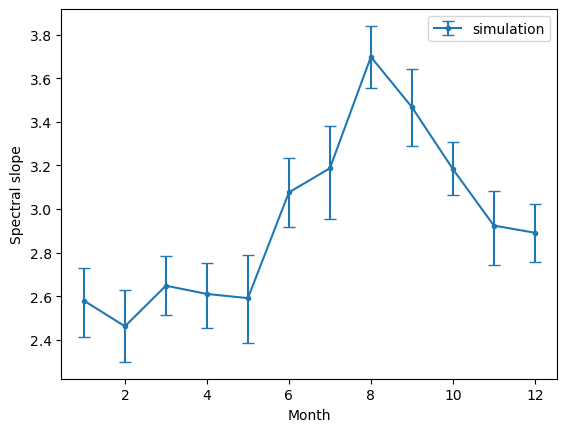

In [70]:
# y = medianm_simOl
# lower = np.array(lowerm_simOl)
# upper = np.array(upperm_simOl)

# yerr = np.vstack([y - lower, upper - y])
# ymedgs = medianm_KE_GS
# ymedgs = KEslopedatags['slopemonthlyke_sim_GS']
ymedgs = slopemonthly_sp_sim_KE_GS
plt.errorbar(
    x, ymedgs, np.vstack([ymedgs - lowerm_KE_GS, upperm_KE_GS - ymedgs]),
    fmt='.-',
    capsize=4,
    label='simulation'
)
# plt.ylim((3,8))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

Text(0, 0.5, 'Spectral slope')

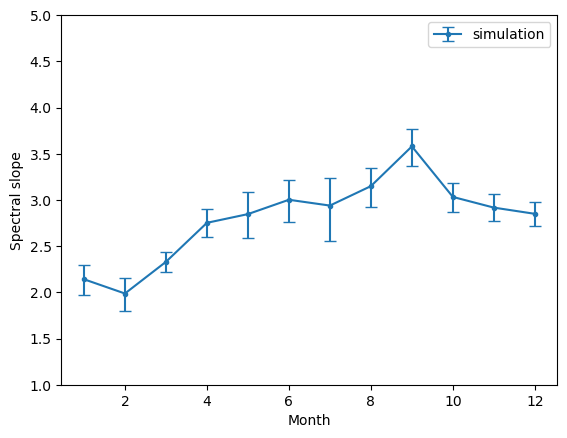

In [65]:
# ymedol = medianm_KE_Ol
# ymedol = KEslopedataol['slopemonthlyke_sim_Ol']
ymedol = slopemonthly_sp_sim_KE_Ol
plt.errorbar(
    x, ymedol, np.vstack([ymedol - lowerm_KE_Ol, upperm_KE_Ol - ymedol]),
    fmt='.-',
    capsize=4,
    label='simulation'
)
# plt.plot(x,KEslopedataol['slopemonthlyke_sim_Ol'])
# plt.ylim((3,8))
plt.ylim((1,5))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

Text(0, 0.5, 'Spectral slope')

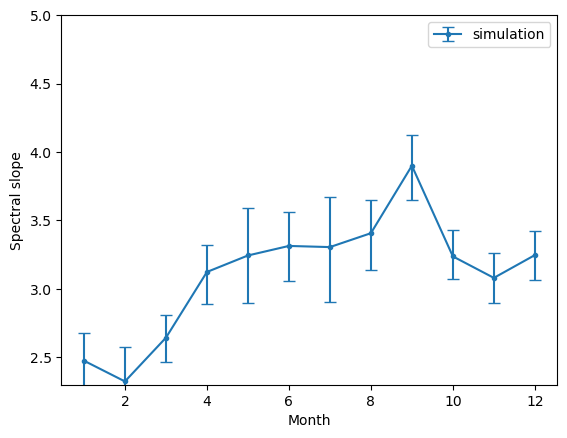

In [40]:
# ymedol = medianm_KE_Ol
ymedol = KEslopedataol['slopemonthlyke_sim_Ol']
plt.errorbar(
    x, ymedol, np.vstack([ymedol - lowerm_KE_Ol, upperm_KE_Ol - ymedol]),
    fmt='.-',
    capsize=4,
    label='simulation'
)
# plt.plot(x,KEslopedataol['slopemonthlyke_sim_Ol'])
# plt.ylim((3,8))
plt.ylim((2.3,5))
plt.legend()
plt.xlabel('Month')
plt.ylabel('Spectral slope')

In [67]:
d = {'lowermGS': lowermGS, 'uppermGS': uppermGS,'lowerm_simGS':lowerm_simGS, \
     'upperm_simGS': upperm_simGS, 'lowermOl': lowermOl,'uppermOl':uppermOl,'lowerm_simOl':lowerm_simOl,'upperm_simOl':upperm_simOl,\
    'lowerm_KE_GS':lowerm_KE_GS,'upperm_KE_GS':upperm_KE_GS,'lowerm_KE_Ol':lowerm_KE_Ol,'upperm_KE_Ol':upperm_KE_Ol}
np.save('slopeuncertains_reselect_rotate_anom.npy', d)